# **Day 94: Project - Flood Mapping in Ghatal using NDWI Change Detection**

**Ghatal** in Paschim Medinipur is one of the most **flood-prone** areas of West Bengal. The Shilabati and Rupnarayan rivers flood the low land almost every monsoon.

In this project, we map a flood by comparing **two satellite images**:
- **Before** the flood (normal water)
- **After** the flood (extra water)

Pixels that are water **after** but were **not water before** are **flooded** land. This method is called **change detection**.

**Data:** Two **synthetic** images (made by code). The village names are real places of the Ghatal area, but their positions on our small grid and all the numbers are **made up** for practice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

rng = np.random.default_rng(21)
rows, cols = 180, 240
y, x = np.mgrid[0:rows, 0:cols]

# A simple height map: a low river valley running from north to south
river_x = 110 + 25 * np.sin(y / 30)
ground_height = 6 + 0.06 * np.abs(x - river_x) + 1.5 * np.sin(x / 17) * np.cos(y / 23) + rng.normal(0, 0.3, (rows, cols))

land_cover = np.full((rows, cols), 3)                          # 3 = paddy fields
land_cover[np.abs(x - river_x) < 6] = 1                        # 1 = river (always water)
settlements = {"Ghatal": (70, 150), "Daspur": (40, 60), "Chandrakona": (150, 35), "Khirpai": (125, 200),
               "Sonakhali": (95, 95), "Kharar": (20, 190), "Ramjibanpur": (160, 150)}
for name, (r0, c0) in settlements.items():
    land_cover[(y - r0) ** 2 + (x - c0) ** 2 < 40] = 4        # 4 = village
print("Grid:", rows, "x", cols, "pixels of 10 m")

Grid: 180 x 240 pixels of 10 m


In [2]:
def make_image(water_mask):
    """Make green and NIR bands for a scene, given where the water is."""
    green = np.where(water_mask, 0.07, np.where(land_cover == 4, 0.12, 0.09))
    nir = np.where(water_mask, 0.03, np.where(land_cover == 4, 0.20, 0.32))
    return green + rng.normal(0, 0.008, green.shape), nir + rng.normal(0, 0.012, nir.shape)

water_before = (land_cover == 1) | (ground_height < 6.3)        # River + a few low ponds
flood_level = 9.5                                               # The water rose to 9.5 m
water_after = (land_cover == 1) | (ground_height < flood_level)

green_before, nir_before = make_image(water_before)
green_after, nir_after = make_image(water_after)

## **Step 1: NDWI for Both Dates**
**NDWI = (Green - NIR) / (Green + NIR)**. Water pixels have **positive** NDWI.

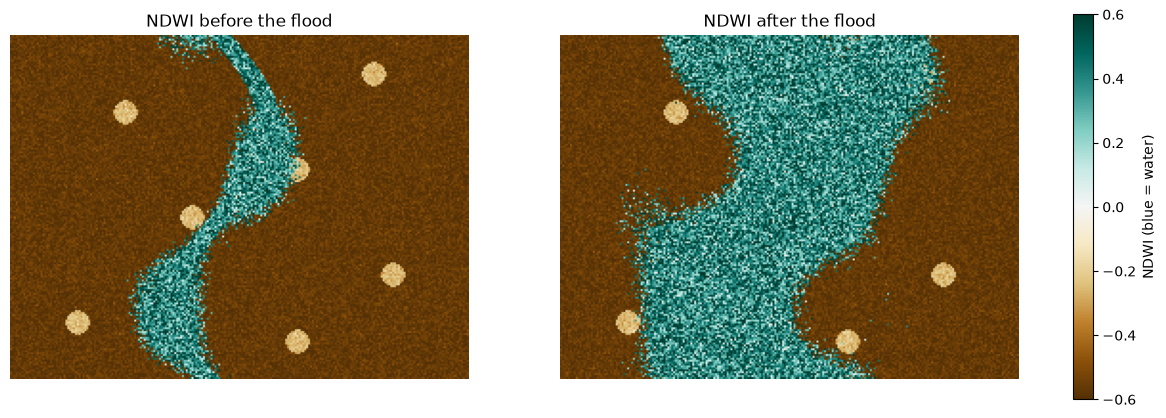

In [3]:
ndwi_before = (green_before - nir_before) / (green_before + nir_before)
ndwi_after = (green_after - nir_after) / (green_after + nir_after)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, img, title in zip(axes, [ndwi_before, ndwi_after], ["NDWI before the flood", "NDWI after the flood"]):
    im = ax.imshow(img, cmap="BrBG", vmin=-0.6, vmax=0.6)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.02, label="NDWI (blue = water)")
plt.show()

## **Step 2: Water Masks and the Flood Map**

In [4]:
THRESHOLD = 0.0
wet_before = ndwi_before > THRESHOLD
wet_after = ndwi_after > THRESHOLD

flooded = wet_after & ~wet_before           # Water now, but not before
permanent = wet_after & wet_before           # Water in both images (river, ponds)

change_map = np.zeros((rows, cols), dtype=int)       # 0 = dry land
change_map[permanent] = 1
change_map[flooded] = 2

pixel_ha = 10 * 10 / 10_000
print(f"Permanent water : {permanent.sum() * pixel_ha:8.1f} ha")
print(f"Newly flooded   : {flooded.sum() * pixel_ha:8.1f} ha")
print(f"Flooded share of the whole area: {flooded.mean():.1%}")

Permanent water :     45.7 ha
Newly flooded   :    139.5 ha
Flooded share of the whole area: 32.3%


Let us understand the code above:
- `~wet_before` means **NOT** water before (`~` flips True and False).
- `wet_after & ~wet_before` keeps only the pixels that **became** water. These are the flooded pixels.
- Each pixel is 10 m x 10 m = 0.01 hectare.

## **Step 3: Which Land Cover Was Flooded?**

In [5]:
lc_names = {1: "River", 3: "Paddy fields", 4: "Villages"}
for code, name in lc_names.items():
    total = (land_cover == code).sum()
    hit = (flooded & (land_cover == code)).sum()
    if code != 1:
        print(f"{name:<13}: {hit * pixel_ha:7.1f} ha flooded out of {total * pixel_ha:7.1f} ha ({hit / total:.0%})")

Paddy fields :   136.3 ha flooded out of   401.9 ha (34%)
Villages     :     3.1 ha flooded out of     8.5 ha (37%)


## **Step 4: Which Villages Are Affected?**
For each village, we check how much of the area **around it** (a circle of 150 m, like a small buffer) is flooded.

In [6]:
records = []
for name, (r0, c0) in settlements.items():
    around = (y - r0) ** 2 + (x - c0) ** 2 < 15 ** 2          # 15 pixels = 150 m
    share = flooded[around].mean()
    status = "Severely affected" if share > 0.5 else "Partly affected" if share > 0.1 else "Safe"
    records.append({"village": name, "flooded_share": round(share * 100, 1), "status": status,
                    "ground_height_m": round(ground_height[r0, c0], 1)})

villages = pd.DataFrame(records).sort_values("flooded_share", ascending=False)
villages

,village,flooded_share,status,ground_height_m
4,Sonakhali,74.6,Severely affected,7.2
5,Kharar,73.3,Severely affected,8.5
0,Ghatal,59.7,Severely affected,6.5
2,Chandrakona,19.7,Partly affected,10.6
6,Ramjibanpur,11.3,Partly affected,10.5
1,Daspur,4.3,Safe,10.3
3,Khirpai,0.0,Safe,11.7


The villages on **lower ground** (closer to the river) are the most affected. This is exactly why disaster teams combine **flood maps** with **elevation data** to plan relief work.

## **Step 5: The Final Flood Map**

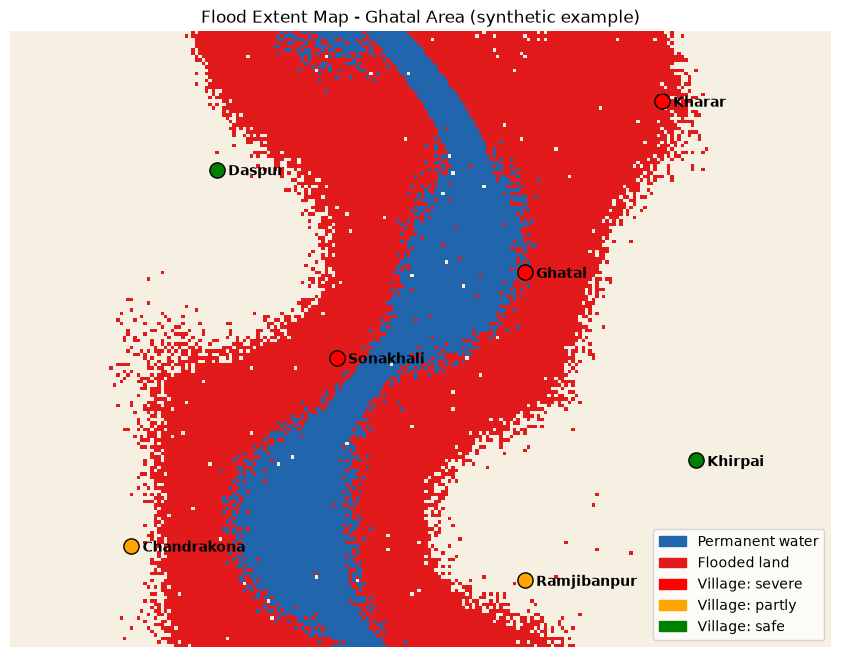

In [7]:
colours = ["#f5f0e1", "#2166ac", "#e31a1c"]            # Dry land, permanent water, flooded
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(change_map, cmap=ListedColormap(colours), vmin=0, vmax=2)

for _, v in villages.iterrows():
    r0, c0 = settlements[v["village"]]
    colour = {"Severely affected": "red", "Partly affected": "orange", "Safe": "green"}[v["status"]]
    ax.scatter(c0, r0, s=120, color=colour, edgecolor="black", zorder=3)
    ax.annotate(v["village"], (c0, r0), xytext=(8, -4), textcoords="offset points", fontsize=10, weight="bold")

ax.legend(handles=[Patch(color=colours[1], label="Permanent water"), Patch(color=colours[2], label="Flooded land"),
                   Patch(color="red", label="Village: severe"), Patch(color="orange", label="Village: partly"),
                   Patch(color="green", label="Village: safe")], loc="lower right")
ax.set_title("Flood Extent Map - Ghatal Area (synthetic example)")
ax.axis("off")
plt.show()

## **In Real Life: Why Radar Satellites Are Used for Floods**
During a flood, the sky is usually **full of clouds**, so optical satellites like Sentinel-2 cannot see the ground. That is why real flood mapping mostly uses **SAR (radar) satellites** like **Sentinel-1** or India's **EOS-04 (RISAT-1A)**, and the upcoming **NISAR**. Radar can see through clouds, day and night.

On a radar image, calm water looks very **dark** (low backscatter), so the same idea works: find pixels that became dark after the flood.

**Real tools:** Google Earth Engine, ISRO's **Bhuvan** portal, and the **NRSC** flood maps are used by disaster management teams in India.

In [8]:
# Quick question
# What does the expression wet_after & ~wet_before find?